# UNIVERSIDAD AUTÓNOMA DEL ESTADO DE MÉXICO

**Asignatura:** Investigación de Operaciones

**Práctica (opcional):** Ruta más corta entre los nodos 1 y 9 con el método Simplex

**Nombre:** KARLA ZARET VAZQUEZ LEDO

**Descripción.** Resolución con el método de tabla visto en clase:

1. Se plantea el modelo de PL (variables xᵢⱼ, función objetivo y restricciones de flujo).
2. Se parte de una **ruta inicial factible** y se completa la **base** con arcos de valor 0.
3. Se arma la **tabla** (filas = básicas, columnas = no básicas, LD y fila de costos reducidos c̄ⱼ).
4. **Entra** la variable con c̄ⱼ más negativo, **sale** la de razón mínima, se **pivotea** y se repite hasta que todos los c̄ⱼ ≥ 0.

## 1. Datos y modelo

Entre los nodos (2,3), (6,7) y (7,8) hay flechas en ambos sentidos; se tomó 3→2 = 4 y 2→3 = 2; 7→6 = 4 y 6→7 = 1; 8→7 = 2 y 7→8 = 3.
Si alguna está al revés, solo se cambia la lista `arcos`.

**Restricciones** (misma convención de clase; formulación de la ruta más corta como PL según Taha, 2012, sec. 6.3.3): en el origen salidas = 1; en el destino entradas = 1; en los intermedios entradas − salidas = 0.
La ecuación del nodo 9 es sobrante (la del nodo 1 es la suma de las demás), así que se elimina y quedan 8 ecuaciones → la base tendrá 8 variables.

In [1]:
import numpy as np
from fractions import Fraction

# ---------------------------------------------------------------- datos de la red
arcos = sorted([
    (1, 2, 4), (1, 3, 2), (2, 3, 2), (3, 2, 4), (2, 4, 7), (3, 4, 9), (3, 5, 6),
    (5, 4, 2), (4, 6, 1), (4, 7, 5), (5, 6, 4), (5, 7, 3), (5, 8, 2),
    (6, 7, 1), (7, 6, 4), (6, 9, 5), (7, 9, 5), (7, 8, 3), (8, 7, 2), (8, 9, 6),
])
origen, destino = 1, 9
nodos = sorted({n for a in arcos for n in a[:2]})
nombres = [f"x{i}{j}" for i, j, _ in arcos]
c = np.array([a[2] for a in arcos], dtype=float)


def construir_modelo(arcos, nodos, origen, destino):
    """Misma convención que en clase:
       origen: salidas = 1 | destino: entradas = 1 | intermedios: entradas - salidas = 0"""
    A = np.zeros((len(nodos), len(arcos)))
    for k, (i, j, _) in enumerate(arcos):
        A[nodos.index(i), k] = 1 if i == origen else -1      # el arco SALE de i
        A[nodos.index(j), k] = -1 if j == origen else 1      # el arco ENTRA a j
    b = np.zeros(len(nodos))
    b[nodos.index(origen)] = 1
    b[nodos.index(destino)] = 1
    return A, b


A_full, b_full = construir_modelo(arcos, nodos, origen, destino)
# la ecuación del nodo destino es redundante (la suma de todas es 0 = 0) -> se quita
keep = [r for r, n in enumerate(nodos) if n != destino]
A, b = A_full[keep], b_full[keep]


def fmt(v):
    f = Fraction(float(v)).limit_denominator(1000)
    return str(f.numerator) if f.denominator == 1 else f"{f.numerator}/{f.denominator}"

In [2]:
import pandas as pd

print("Minimizar z =", " + ".join(f"{int(cc)}{n}" for n, cc in zip(nombres, c)).replace("1x", "x"))
print("\nSujeto a:")
for r, n in enumerate(nodos):
    lado = " ".join((("+ " if v > 0 else "- ") + nombres[k]) for k, v in enumerate(A_full[r]) if v)
    print(f"  nodo {n}: {lado} = {int(b_full[r])}")
print("\nx_ij >= 0")

Minimizar z = 4x12 + 2x13 + 2x23 + 7x24 + 4x32 + 9x34 + 6x35 + x46 + 5x47 + 2x54 + 4x56 + 3x57 + 2x58 + x67 + 5x69 + 4x76 + 3x78 + 5x79 + 2x87 + 6x89

Sujeto a:
  nodo 1: + x12 + x13 = 1
  nodo 2: + x12 - x23 - x24 + x32 = 0
  nodo 3: + x13 + x23 - x32 - x34 - x35 = 0
  nodo 4: + x24 + x34 - x46 - x47 + x54 = 0
  nodo 5: + x35 - x54 - x56 - x57 - x58 = 0
  nodo 6: + x46 + x56 - x67 - x69 + x76 = 0
  nodo 7: + x47 + x57 + x67 - x76 - x78 - x79 + x87 = 0
  nodo 8: + x58 + x78 - x87 - x89 = 0
  nodo 9: + x69 + x79 + x89 = 1

x_ij >= 0


## 2. Ruta inicial y base

Ruta inicial: **1 → 2 → 4 → 6 → 9** (4 + 7 + 1 + 5 = 17). Sus arcos valen 1.
Se completan 4 arcos con valor 0 que lleguen a los nodos que faltan (3, 5, 7 y 8): `x32`, `x54`, `x76`, `x87`. Así la base tiene 8 variables y es invertible.

In [3]:
idx = {n: k for k, n in enumerate(nombres)}
base0 = [idx[x] for x in ["x12", "x24", "x32", "x46", "x54", "x69", "x76", "x87"]]

print("Base:       ", [nombres[j] for j in sorted(base0)])
print("No básicas: ", [nombres[j] for j in range(len(arcos)) if j not in base0], "= 0")
print("Solución inicial: x12 = x24 = x46 = x69 = 1")
print("z inicial =", c[base0] @ np.linalg.solve(A[:, base0], b))

Base:        ['x12', 'x24', 'x32', 'x46', 'x54', 'x69', 'x76', 'x87']
No básicas:  ['x13', 'x23', 'x34', 'x35', 'x47', 'x56', 'x57', 'x58', 'x67', 'x78', 'x79', 'x89'] = 0
Solución inicial: x12 = x24 = x46 = x69 = 1
z inicial = 17.0


## 3. Simplex en forma de tabla

`simplex_tabla` hace en cada iteración:

- B⁻¹A y B⁻¹b → la tabla (columna **LD**).
- c̄ⱼ = cⱼ − c_B·B⁻¹aⱼ → fila de costos reducidos.
- **Entra** el de c̄ⱼ más negativo; **sale** el de razón mínima LD/(coeficiente positivo); empate → menor índice.

In [4]:
def simplex_tabla(c, A, b, base0, tol=1e-9, max_iter=100):
    """Simplex en forma de tabla: filas = variables básicas, columnas = no básicas.
       Entra la variable con c̄ más negativo; sale la de razón mínima (empate: menor índice)."""
    m, n = A.shape
    base = sorted(base0)
    pasos = []
    for _ in range(max_iter):
        Binv = np.linalg.inv(A[:, base])
        T = Binv @ A                      # B^-1 · A
        xB = Binv @ b                     # lado derecho (LD)
        cbar = c - c[base] @ T            # costos reducidos c̄_j = c_j - c_B · B^-1 a_j
        z = float(c[base] @ xB)
        nb = [j for j in range(n) if j not in base]
        p = dict(base=list(base), nb=nb, T=T[:, nb], xB=xB, cbar=cbar[nb], z=z,
                 entra=None, sale=None, fila=None, razones=[], calc=None)
        neg = [j for j in nb if cbar[j] < -tol]
        if not neg:
            pasos.append(p)
            return pasos
        s = min(neg, key=lambda j: (cbar[j], j))
        razones = [(xB[i] / T[i, s], base[i], i) for i in range(m) if T[i, s] > tol]
        if not razones:
            raise ValueError("Problema no acotado")
        rmin = min(rr[0] for rr in razones)
        r = min((rr for rr in razones if abs(rr[0] - rmin) < tol), key=lambda t: t[1])[2]
        p.update(entra=s, sale=base[r], fila=r, razones=razones, rmin=rmin,
                 calc=(c[s], [(c[base[i]], T[i, s]) for i in range(m) if abs(T[i, s]) > tol]))
        pasos.append(p)
        base[r] = s
        base.sort()
    raise RuntimeError("No converge")

## 4. Iteraciones (con colores)

🟩 columna que entra · 🟥 fila que sale · 🟨 pivote · 🟪 fila de costos reducidos

In [5]:
from IPython.display import display, HTML

TEMAS = ["#6a4c93", "#1f7a8c", "#d9722b", "#b83b6b", "#3a8d5c", "#2f64b0"]

def tabla_df(p):
    cols = [nombres[j] for j in p["nb"]]
    filas = [nombres[j] for j in p["base"]]
    data = [[fmt(v) for v in row] + [fmt(p["xB"][i])] for i, row in enumerate(p["T"])]
    data.append([fmt(v) for v in p["cbar"]] + [f"z = {fmt(p['z'])}"])
    return pd.DataFrame(data, index=filas + ["c̄j"], columns=cols + ["LD"])

def mostrar_tabla(p, k):
    df = tabla_df(p)
    e = p["entra"]
    ce = df.columns[p["nb"].index(e)] if e is not None else None
    re = df.index[p["fila"]] if e is not None else None
    def estilo(_):
        s = pd.DataFrame("", index=df.index, columns=df.columns)
        s.loc["c̄j", :] = "background-color:#e9e1f7;font-weight:bold"
        if e is not None:
            s.loc[df.index[:-1], ce] = "background-color:#c9ecd0"
            s.loc[re, :] = "background-color:#fbcaca"
            s.loc[re, ce] = "background-color:#ffe066;font-weight:bold;border:2px solid #c0392b"
        return s
    sty = (df.style.apply(estilo, axis=None)
             .set_table_styles([{"selector": "th.col_heading", "props": f"background-color:{TEMAS[k % 6]};color:white;text-align:center"},
                                {"selector": "th.row_heading", "props": "font-weight:bold"},
                                {"selector": "td", "props": "text-align:center;min-width:26px;padding:3px 4px;font-size:10.5px"}]))
    display(sty)

def z_expr(p):
    s = f"z = {fmt(p['z'])}"
    for j, cb in zip(p["nb"], p["cbar"]):
        v = abs(cb); coef = "" if abs(v - 1) < 1e-9 else fmt(v) + "·"
        s += f" + 0·{nombres[j]}" if v < 1e-9 else f" {'-' if cb < 0 else '+'} {coef}{nombres[j]}"
    return s

def mostrar_paso(k):
    p = pasos[k]
    nombre = "Tabla inicial" if k == 0 else f"Tabla {k}"
    print(f"===== {nombre}" + (" (óptima)" if p["entra"] is None else "") + " =====")
    mostrar_tabla(p, k)
    print(z_expr(p))
    if p["entra"] is None:
        print("Todos los c̄j >= 0 -> solución ÓPTIMA.")
        return
    e, s_ = nombres[p["entra"]], nombres[p["sale"]]
    rz = ", ".join(f"{fmt(p['xB'][i])}/{fmt(p['T'][i][p['nb'].index(p['entra'])])} ({nombres[p['base'][i]]})" for _, _, i in p["razones"])
    print(f"Entra: {e}  (c̄ = {fmt(p['cbar'][p['nb'].index(p['entra'])])}, el más negativo)")
    print(f"Sale:  min{{ {rz} }} = {fmt(p['rmin'])}  ->  sale {s_}")
    print(f"Pivote: el {fmt(p['T'][p['fila']][p['nb'].index(p['entra'])])} en la fila {s_} y la columna {e}")
    print(f"z pasa de {fmt(p['z'])} a {fmt(pasos[k + 1]['z'])}")

In [6]:
pasos = simplex_tabla(c, A, b, base0)
print(f"Pivoteos: {len(pasos) - 1}")

Pivoteos: 4


In [7]:
mostrar_paso(0)

===== Tabla inicial =====


,x13,x23,x34,x35,x47,x56,x57,x58,x67,x78,x79,x89,LD
x12,1,0,0,0,0,0,0,0,0,0,0,0,1
x24,0,0,1,1,0,0,0,0,0,0,0,0,1
x32,-1,-1,1,1,0,0,0,0,0,0,0,0,0
x46,0,0,0,0,1,1,1,1,0,0,0,0,1
x54,0,0,0,-1,0,1,1,1,0,0,0,0,0
x69,0,0,0,0,0,0,0,0,0,0,1,1,1
x76,0,0,0,0,-1,0,-1,-1,-1,0,1,1,0
x87,0,0,0,0,0,0,0,-1,0,-1,0,1,0
c̄j,2,6,-2,-3,8,1,4,5,5,5,-4,-5,z = 17


z = 17 + 2·x13 + 6·x23 - 2·x34 - 3·x35 + 8·x47 + x56 + 4·x57 + 5·x58 + 5·x67 + 5·x78 - 4·x79 - 5·x89
Entra: x89  (c̄ = -5, el más negativo)
Sale:  min{ 1/1 (x69), 0/1 (x76), 0/1 (x87) } = 0  ->  sale x76
Pivote: el 1 en la fila x76 y la columna x89
z pasa de 17 a 17


In [8]:
mostrar_paso(1)

===== Tabla 1 =====


,x13,x23,x34,x35,x47,x56,x57,x58,x67,x76,x78,x79,LD
x12,1,0,0,0,0,0,0,0,0,0,0,0,1
x24,0,0,1,1,0,0,0,0,0,0,0,0,1
x32,-1,-1,1,1,0,0,0,0,0,0,0,0,0
x46,0,0,0,0,1,1,1,1,0,0,0,0,1
x54,0,0,0,-1,0,1,1,1,0,0,0,0,0
x69,0,0,0,0,1,0,1,1,1,-1,0,0,1
x87,0,0,0,0,1,0,1,0,1,-1,-1,-1,0
x89,0,0,0,0,-1,0,-1,-1,-1,1,0,1,0
c̄j,2,6,-2,-3,3,1,-1,0,0,5,5,1,z = 17


z = 17 + 2·x13 + 6·x23 - 2·x34 - 3·x35 + 3·x47 + x56 - x57 + 0·x58 + 0·x67 + 5·x76 + 5·x78 + x79
Entra: x35  (c̄ = -3, el más negativo)
Sale:  min{ 1/1 (x24), 0/1 (x32) } = 0  ->  sale x32
Pivote: el 1 en la fila x32 y la columna x35
z pasa de 17 a 17


In [9]:
mostrar_paso(2)

===== Tabla 2 =====


,x13,x23,x32,x34,x47,x56,x57,x58,x67,x76,x78,x79,LD
x12,1,0,0,0,0,0,0,0,0,0,0,0,1
x24,1,1,-1,0,0,0,0,0,0,0,0,0,1
x35,-1,-1,1,1,0,0,0,0,0,0,0,0,0
x46,0,0,0,0,1,1,1,1,0,0,0,0,1
x54,-1,-1,1,1,0,1,1,1,0,0,0,0,0
x69,0,0,0,0,1,0,1,1,1,-1,0,0,1
x87,0,0,0,0,1,0,1,0,1,-1,-1,-1,0
x89,0,0,0,0,-1,0,-1,-1,-1,1,0,1,0
c̄j,-1,3,3,1,3,1,-1,0,0,5,5,1,z = 17


z = 17 - x13 + 3·x23 + 3·x32 + x34 + 3·x47 + x56 - x57 + 0·x58 + 0·x67 + 5·x76 + 5·x78 + x79
Entra: x13  (c̄ = -1, el más negativo)
Sale:  min{ 1/1 (x12), 1/1 (x24) } = 1  ->  sale x12
Pivote: el 1 en la fila x12 y la columna x13
z pasa de 17 a 16


In [10]:
mostrar_paso(3)

===== Tabla 3 =====


,x12,x23,x32,x34,x47,x56,x57,x58,x67,x76,x78,x79,LD
x13,1,0,0,0,0,0,0,0,0,0,0,0,1
x24,-1,1,-1,0,0,0,0,0,0,0,0,0,0
x35,1,-1,1,1,0,0,0,0,0,0,0,0,1
x46,0,0,0,0,1,1,1,1,0,0,0,0,1
x54,1,-1,1,1,0,1,1,1,0,0,0,0,1
x69,0,0,0,0,1,0,1,1,1,-1,0,0,1
x87,0,0,0,0,1,0,1,0,1,-1,-1,-1,0
x89,0,0,0,0,-1,0,-1,-1,-1,1,0,1,0
c̄j,1,3,3,1,3,1,-1,0,0,5,5,1,z = 16


z = 16 + x12 + 3·x23 + 3·x32 + x34 + 3·x47 + x56 - x57 + 0·x58 + 0·x67 + 5·x76 + 5·x78 + x79
Entra: x57  (c̄ = -1, el más negativo)
Sale:  min{ 1/1 (x46), 1/1 (x54), 1/1 (x69), 0/1 (x87) } = 0  ->  sale x87
Pivote: el 1 en la fila x87 y la columna x57
z pasa de 16 a 16


In [11]:
mostrar_paso(4)

===== Tabla 4 (óptima) =====


,x12,x23,x32,x34,x47,x56,x58,x67,x76,x78,x79,x87,LD
x13,1,0,0,0,0,0,0,0,0,0,0,0,1
x24,-1,1,-1,0,0,0,0,0,0,0,0,0,0
x35,1,-1,1,1,0,0,0,0,0,0,0,0,1
x46,0,0,0,0,0,1,1,-1,1,1,1,-1,1
x54,1,-1,1,1,-1,1,1,-1,1,1,1,-1,1
x57,0,0,0,0,1,0,0,1,-1,-1,-1,1,0
x69,0,0,0,0,0,0,1,0,0,1,1,-1,1
x89,0,0,0,0,0,0,-1,0,0,-1,0,1,0
c̄j,1,3,3,1,4,1,0,1,4,4,0,1,z = 16


z = 16 + x12 + 3·x23 + 3·x32 + x34 + 4·x47 + x56 + 0·x58 + x67 + 4·x76 + 4·x78 + 0·x79 + x87
Todos los c̄j >= 0 -> solución ÓPTIMA.


## 5. Solución

In [12]:
fin = pasos[-1]
x = np.zeros(len(arcos))
for i, bj in enumerate(fin["base"]):
    x[bj] = fin["xB"][i]
usados = [(i, j, cc) for (i, j, cc), xv in zip(arcos, x) if xv > 0.5]
print("Variables con valor 1:", [nombres[k] for k, xv in enumerate(x) if xv > 0.5])

sig = {i: j for i, j, _ in usados}
ruta, nodo = [origen], origen
while nodo != destino:
    nodo = sig[nodo]
    ruta.append(nodo)
print("Ruta más corta:", " -> ".join(map(str, ruta)))
print("Distancia total z* =", fin["z"])

Variables con valor 1: ['x13', 'x35', 'x46', 'x54', 'x69']
Ruta más corta: 1 -> 3 -> 5 -> 4 -> 6 -> 9
Distancia total z* = 16.0


## 6. Verificación

Se compara con el simplex de SciPy (`linprog` con `highs-ds`, SciPy, s. f.) y con el algoritmo de Dijkstra (1959) implementado en NetworkX (NetworkX, s. f.). Hay rutas empatadas porque la tabla óptima tiene costos reducidos 0 en variables no básicas.

In [13]:
import networkx as nx
from scipy.optimize import linprog

res = linprog(c, A_eq=A, b_eq=b, bounds=(0, None), method="highs-ds")
G = nx.DiGraph(); G.add_weighted_edges_from(arcos)
print("linprog (simplex HiGHS):", res.fun)
print("Dijkstra (NetworkX):    ", nx.shortest_path_length(G, origen, destino, weight="weight"))
print("Rutas óptimas (todas con la misma distancia):")
for p_ in nx.all_shortest_paths(G, origen, destino, weight="weight"):
    print("  ", " -> ".join(map(str, p_)))

linprog (simplex HiGHS): 16.0
Dijkstra (NetworkX):     16
Rutas óptimas (todas con la misma distancia):
   1 -> 3 -> 5 -> 8 -> 9
   1 -> 3 -> 5 -> 7 -> 9
   1 -> 3 -> 5 -> 4 -> 6 -> 9


## 7. Gráfica

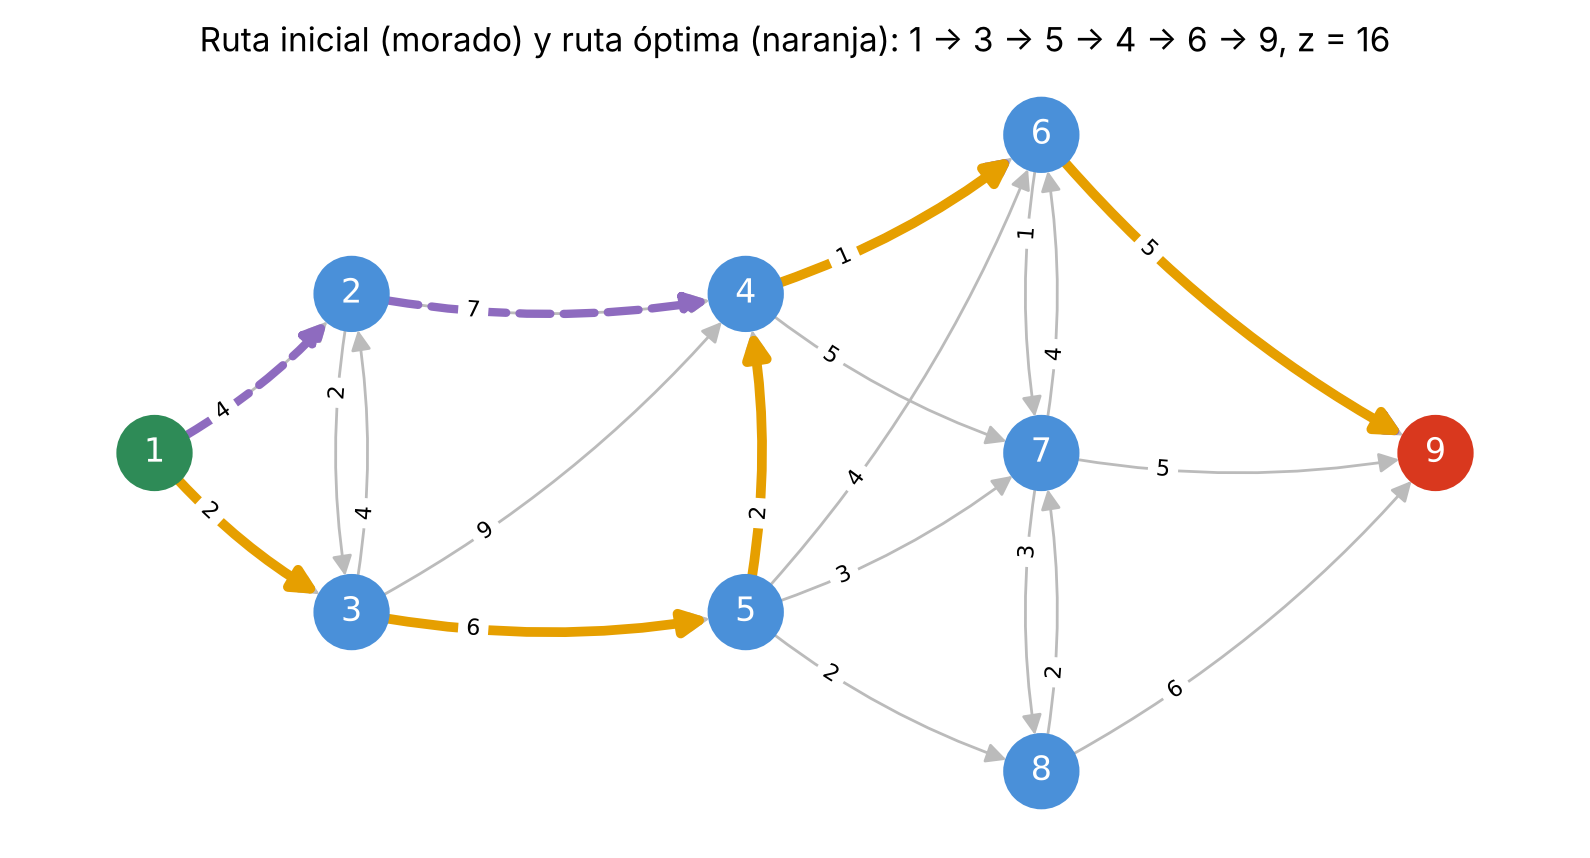

In [14]:
import matplotlib.pyplot as plt

pos = {1: (0, 0), 2: (1, 1), 3: (1, -1), 4: (3, 1), 5: (3, -1), 6: (4.5, 2), 7: (4.5, 0), 8: (4.5, -2), 9: (6.5, 0)}
ruta0 = [1, 2, 4, 6, 9]
fig, ax = plt.subplots(figsize=(10, 5))
cols = ["#2e8b57" if n == origen else "#d9381e" if n == destino else "#4a90d9" for n in G]
nx.draw_networkx_nodes(G, pos, node_color=cols, node_size=700, ax=ax)
nx.draw_networkx_labels(G, pos, font_color="white", ax=ax)
kw = dict(node_size=700, connectionstyle="arc3,rad=0.1", ax=ax)
nx.draw_networkx_edges(G, pos, edge_color="#bbbbbb", arrowsize=15, **kw)
nx.draw_networkx_edges(G, pos, edgelist=list(zip(ruta0[:-1], ruta0[1:])), edge_color="#8e6bbf", width=3, style="dashed", arrowsize=16, **kw)
nx.draw_networkx_edges(G, pos, edgelist=list(zip(ruta[:-1], ruta[1:])), edge_color="#e69f00", width=3.5, arrowsize=18, **kw)
nx.draw_networkx_edge_labels(G, pos, edge_labels={(i, j): cc for i, j, cc in arcos}, font_size=8,
                             label_pos=0.3, connectionstyle="arc3,rad=0.1", ax=ax)
ax.set_title(f"Ruta inicial (morado) y ruta óptima (naranja): {' -> '.join(map(str, ruta))}, z = {fin['z']:.0f}")
ax.axis("off")
plt.show()

## Interpretación de resultados

La red tiene **9 nodos y 20 arcos dirigidos**. El método Simplex, partiendo de la ruta inicial 1→2→4→6→9 (distancia 17), llegó en **4 pivoteos** a la ruta **1→3→5→4→6→9 con distancia mínima 16**. Dos de esos pivoteos fueron degenerados (z no cambió), algo normal en rutas más cortas porque la base tiene 8 variables pero la ruta solo usa 5 arcos. El resultado coincide con `linprog` y con Dijkstra.

En la tabla óptima hay costos reducidos iguales a 0 en variables no básicas (x58 y x79), lo que indica **soluciones óptimas alternativas**: las rutas 1→3→5→7→9 y 1→3→5→8→9 también miden 16.

**Aplicación en TI:** este modelo representa una red de computadoras donde los nodos son equipos o routers y los arcos son enlaces con su costo o latencia; la ruta más corta es el camino por el que conviene enviar la información.

**Conclusión individual:** En esta práctica aprendí que el problema de la ruta más corta se puede resolver como un problema de programación lineal, y no solo con algoritmos de grafos como Dijkstra. Lo más importante fue entender el procedimiento del Simplex en forma de tabla: elegir una ruta inicial, completar la base con arcos de valor 0, calcular los costos reducidos, decidir qué variable entra y cuál sale con la razón mínima, y pivotear hasta que ya no hay costos reducidos negativos. Me llamó la atención que varios pivoteos no cambiaron el valor de z y que al final aparecieron rutas distintas con la misma distancia; comprobar el resultado con Dijkstra y con `linprog` me dio confianza de que la tabla estaba bien hecha. En TI esto se relaciona con el enrutamiento en redes de computadoras, donde conviene enviar la información por el camino de menor costo.

## Referencias

- Bazaraa, M. S. y Jarvis, J. J. (1981). *Programación lineal y flujo en redes*. Limusa.
- Dijkstra, E. W. (1959). A note on two problems in connexion with graphs. *Numerische Mathematik, 1*, 269–271. https://doi.org/10.1007/BF01386390
- NetworkX developers. (s. f.). *Shortest paths*. NetworkX documentation. https://networkx.org/documentation/stable/reference/algorithms/shortest_paths.html
- SciPy community. (s. f.). *scipy.optimize.linprog – method='highs-ds'*. SciPy documentation. https://docs.scipy.org/doc/scipy/reference/optimize.linprog-highs-ds.html
- Taha, H. A. (2012). *Investigación de operaciones* (9.ª ed.). Pearson Educación. (Sec. 6.3.3: Formulación de programación lineal del problema de la ruta más corta.)